# 02 · Quantum Hadamard Edge Detection (QHED)

**Phase A2: a quantum-assisted image operation.** Pipeline: classical preprocessing → amplitude encoding →
H · decrement · H → measurement → classical post-processing (threshold) → comparison with classical edges.

After the circuit, the amplitude of basis state $|2i+1\rangle$ (ancilla = 1) equals $(c_i - c_{i+1})/2$. So the
odd outcomes hold every horizontal neighbour difference. Running the circuit on the transposed image gives the
vertical differences.

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "..")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
from qipbench import images, edge
img = images.preprocess(images.load_standard("blocks"), 16).quantized
qc, norm = edge.qhed_circuit(img)
print("qubits:", qc.num_qubits, "(8 data + 1 ancilla) for a 16x16 image; norm =", round(norm, 4))

qubits: 9 (8 data + 1 ancilla) for a 16x16 image; norm = 7.1598


## 1. The decrement (cyclic shift) unitary, verified on basis states

In [2]:
from qiskit.quantum_info import Statevector
dec = edge.increment(3).inverse()
print(dec.draw("text"))
print([int(np.argmax(Statevector.from_int(x, 8).evolve(dec).probabilities())) for x in range(8)])

     ┌───┐          
q_0: ┤ X ├──■────■──
     └───┘┌─┴─┐  │  
q_1: ─────┤ X ├──■──
          └───┘┌─┴─┐
q_2: ──────────┤ X ├
               └───┘
[7, 0, 1, 2, 3, 4, 5, 6]


## 2. Exact (infinite-shot) QHED equals the classical forward differences

max |quantum - classical| gradient: 3.2357018050322274e-12


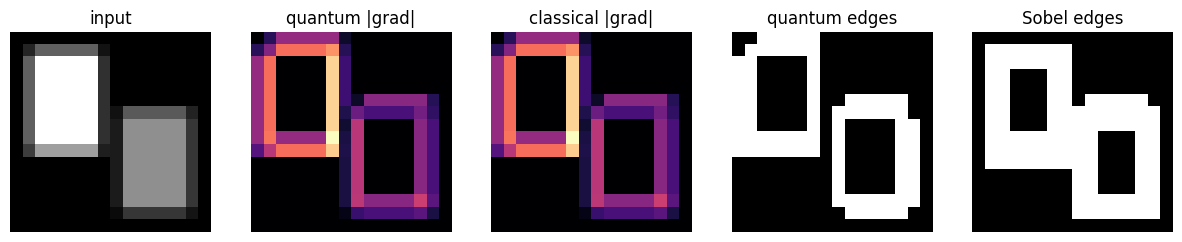

In [3]:
r = edge.detect(img, threshold=0.2, shots=None)
print("max |quantum - classical| gradient:", np.abs(r.magnitude - r.classical_magnitude).max())
fig, ax = plt.subplots(1, 5, figsize=(15, 3))
for a, (t, im) in zip(ax, [("input", img), ("quantum |grad|", r.magnitude), ("classical |grad|", r.classical_magnitude),
                          ("quantum edges", r.edges), ("Sobel edges", r.sobel_edges)]):
    a.imshow(im, cmap="gray" if "edges" in t or t == "input" else "magma"); a.set_title(t); a.axis("off")
plt.show()

## 3. Finite shots: how many measurements does edge detection need?

In [4]:
import pandas as pd
rows = []
for shots in [256, 1024, 4096, 16384, 65536, None]:
    m = edge.detect(img, threshold=0.2, shots=shots, seed=3).metrics
    rows.append({"shots/scan": shots or "exact", "edge F1": m["edge_f1"], "precision": m["edge_precision"],
                 "recall": m["edge_recall"], "gradient MAE": m["gradient_mae"]})
pd.DataFrame(rows)

,shots/scan,edge F1,precision,recall,gradient MAE
0,256,0.444444,1.000000,0.285714,1.351403e-01
1,1024,0.797203,0.966102,0.678571,7.821778e-02
2,4096,0.910180,0.915663,0.904762,4.214113e-02
3,16384,0.919255,0.961039,0.880952,1.958587e-02
4,65536,0.957576,0.975309,0.940476,8.803219e-03
5,exact,1.000000,1.000000,1.000000,1.689715e-13


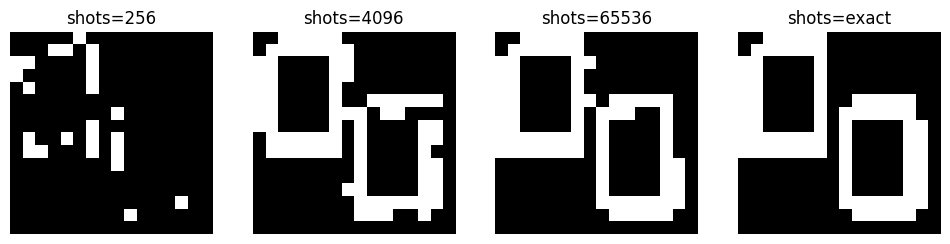

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, s in zip(ax, [256, 4096, 65536, None]):
    a.imshow(edge.detect(img, 0.2, s, seed=3).edges, cmap="gray"); a.set_title(f"shots={s or 'exact'}"); a.axis("off")
plt.show()

## 4. Natural image and noise

In [6]:
cam = images.preprocess(images.load_standard("camera"), 8).quantized
for noise in [0, 1e-4, 1e-3, 3e-3]:
    m = edge.detect(cam, 0.15, 16384, noise, seed=0).metrics
    print(f"noise={noise:<7} F1={m['edge_f1']:.3f}  fidelity={m['fidelity']:.3f}  CNOTs/circuit={m['cx']}")

noise=0       F1=0.920  fidelity=0.998  CNOTs/circuit=270


noise=0.0001  F1=0.676  fidelity=0.994  CNOTs/circuit=270


noise=0.001   F1=0.552  fidelity=0.947  CNOTs/circuit=270


noise=0.003   F1=0.552  fidelity=0.842  CNOTs/circuit=270


**Discussion.** Edge probability scales with the *squared* intensity difference, so weak edges need many
more shots than strong ones. The decrement ladder of multi-controlled X gates dominates the CNOT count and so
sets the noise sensitivity. Classical post-processing (the threshold) is part of the algorithm: it trades
precision against recall.